# How network structure changes shock loss

This native Julia companion preserves the clearing equation, liability rows, balance-sheet generation, original seeds, shock sizes and strict default threshold. Shared primitive normal and uniform draws preserve the original generated inputs; Julia computes all balance sheets, payments and summaries. Displayed institution and draw labels retain the original zero-based convention. Julia ArgumentError corresponds to Python ValueError. The native conic solver uses stricter internal accuracy while retaining the public feasibility tolerance and decision rule. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## Four Generated Network Structures

The generated experiment uses twelve institutions. Every row of the relative-liability matrix has internal share $0.8$:

$$
\sum_{j=1}^{12}\Pi_{ij}=0.8,
$$

so the remaining $0.2$ of each payment goes outside the network. Ring, complete, core-periphery, and two-community structures alter only the allocation of the internal share. Nominal liabilities and external assets are generated visibly from fixed seeds. They are stylized values, not estimates for actual institutions.

Row,Item,Value
,String,String
1,Data source,Generated in this notebook
2,Public bilateral panel found,No
3,Reason generation is necessary,Public aggregates do not identify bilateral nominal liabilities
4,Institutions,12
5,Internal liability share,0.8
6,Outside liability share,0.2
7,Random seed,2902
8,Download during execution,None


Row,Structure,Directed internal links,Mean positive share,Mean row squared concentration,Largest row share
,String,Int64,Float64,Float64,Float64
1,Ring,12,0.8,0.64,0.8
2,Complete,132,0.0727273,0.0581818,0.0727273
3,Core-periphery,132,0.0727273,0.0951492,0.16
4,Two-community,132,0.0727273,0.09488,0.136


Row,Structure,Smallest row sum,Largest row sum,Diagonal maximum,Nonnegative,Row contract passes
,String,Float64,Float64,Float64,String,String
1,Ring,0.8,0.8,0.0,Pass,Pass
2,Complete,0.8,0.8,0.0,Pass,Pass
3,Core-periphery,0.8,0.8,0.0,Pass,Pass
4,Two-community,0.8,0.8,0.0,Pass,Pass


Row,Structure,Total nominal liabilities,Total external assets,Baseline total unpaid,Baseline default count,Fixed point residual
,String,Float64,Float64,Float64,Int64,Float64
1,Ring,12.0,7.86959,0.0,0,0.0
2,Complete,12.0,7.86959,6.10623e-16,0,4.44089e-16
3,Core-periphery,12.0,7.86959,0.0,0,0.0
4,Two-community,12.0,7.86959,1.11022e-16,0,1.11022e-16


GKS: could not find font bold.ttf

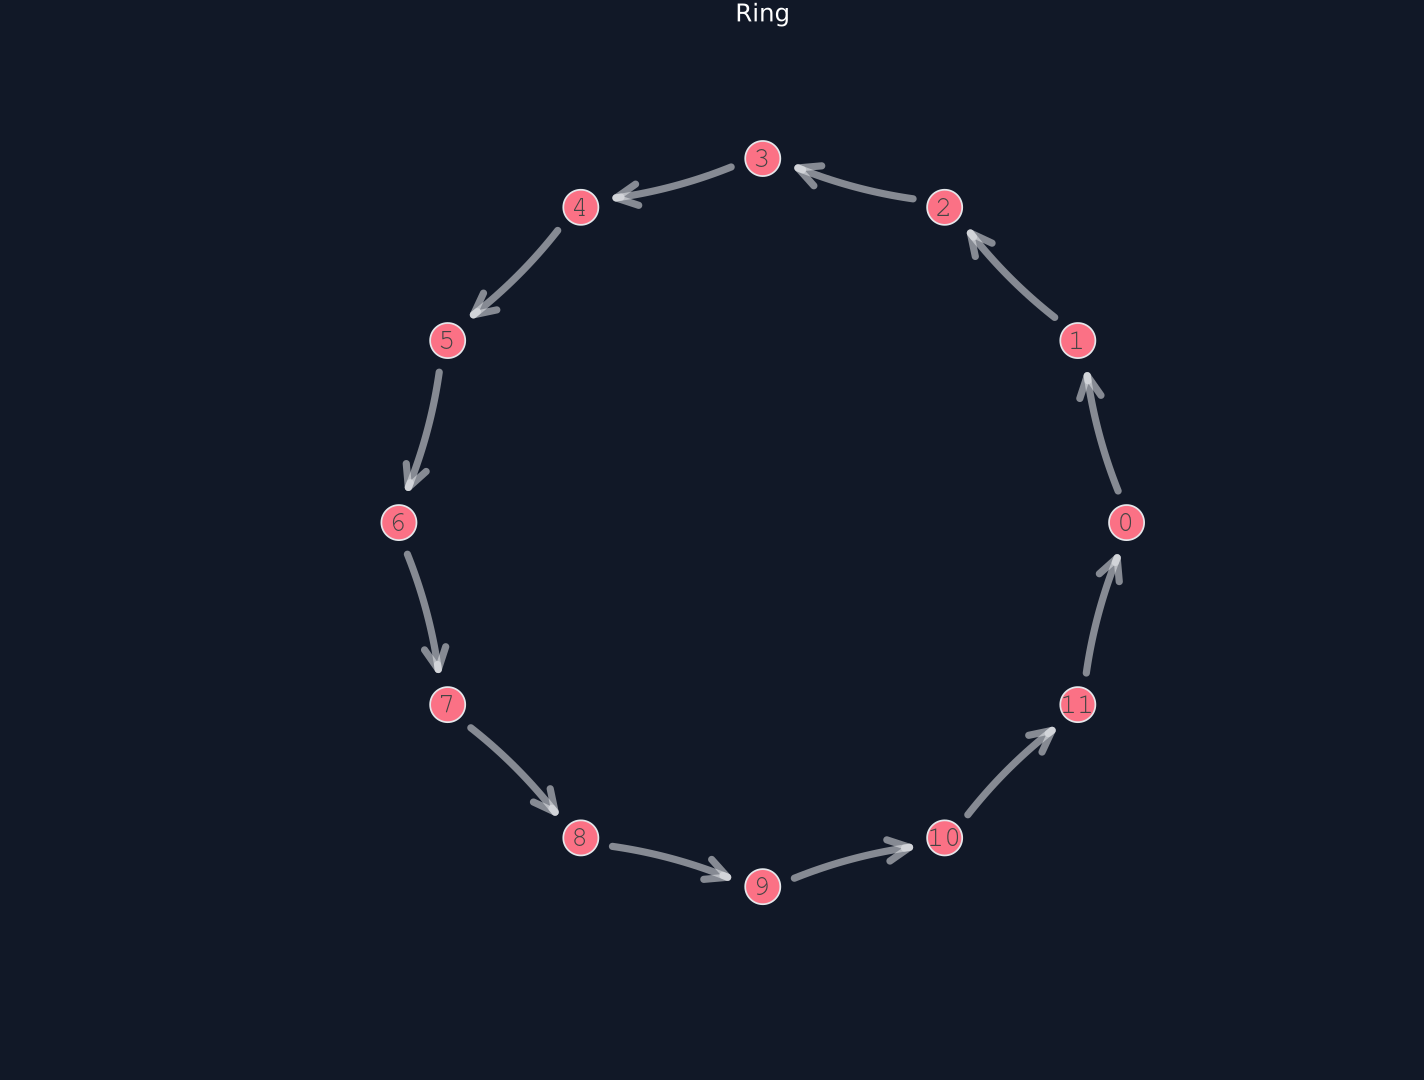

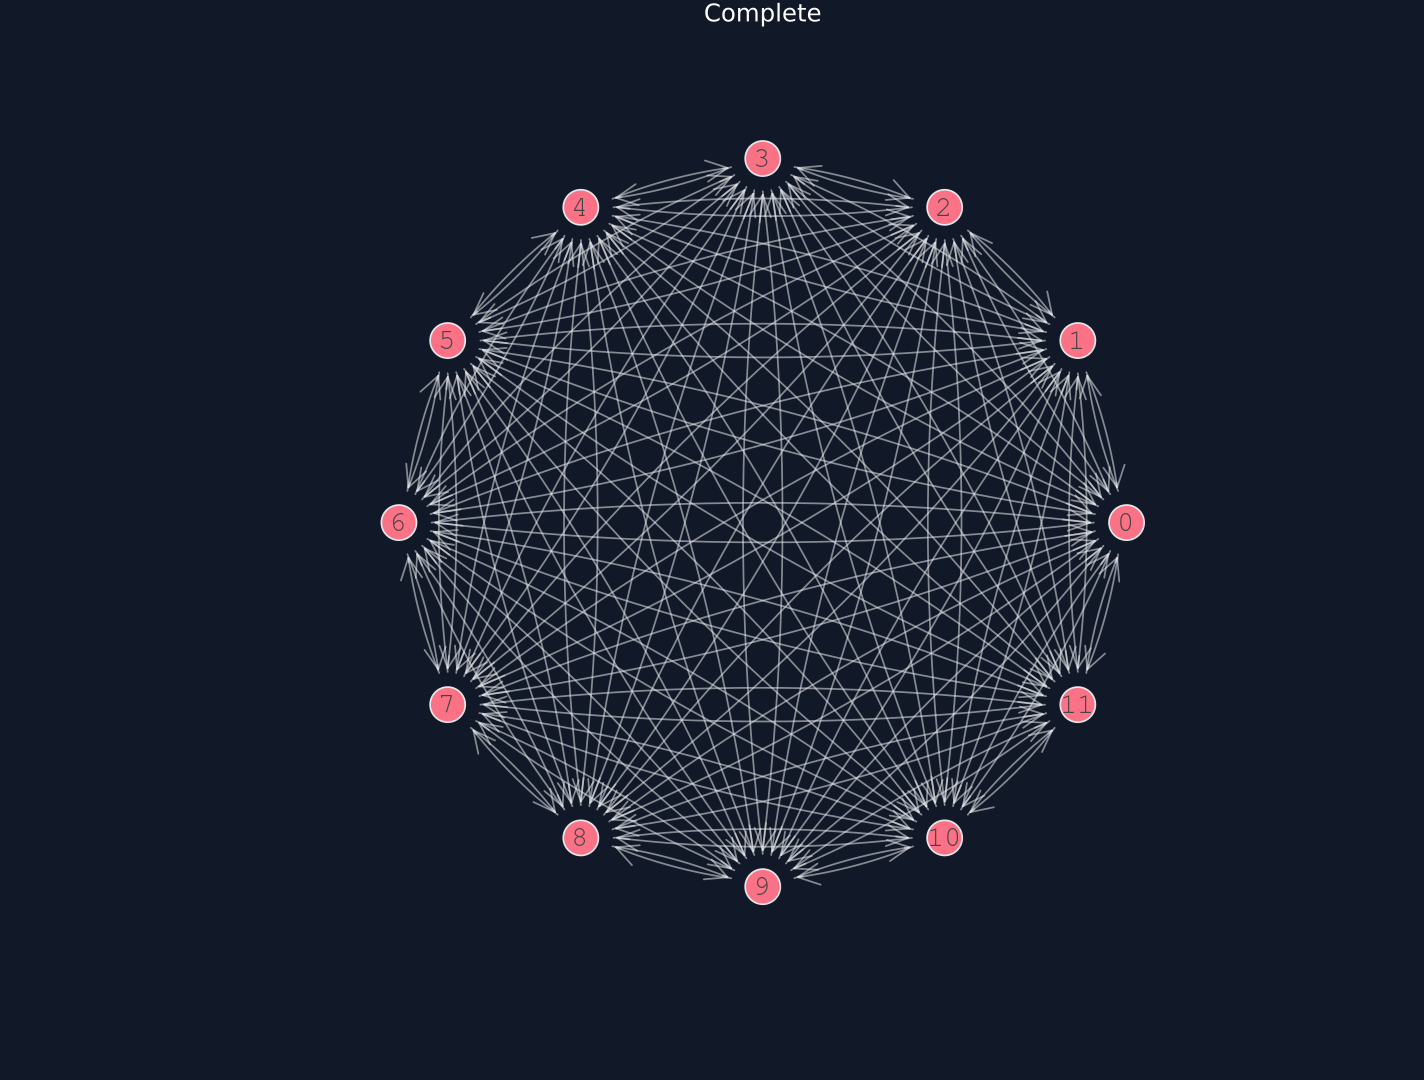

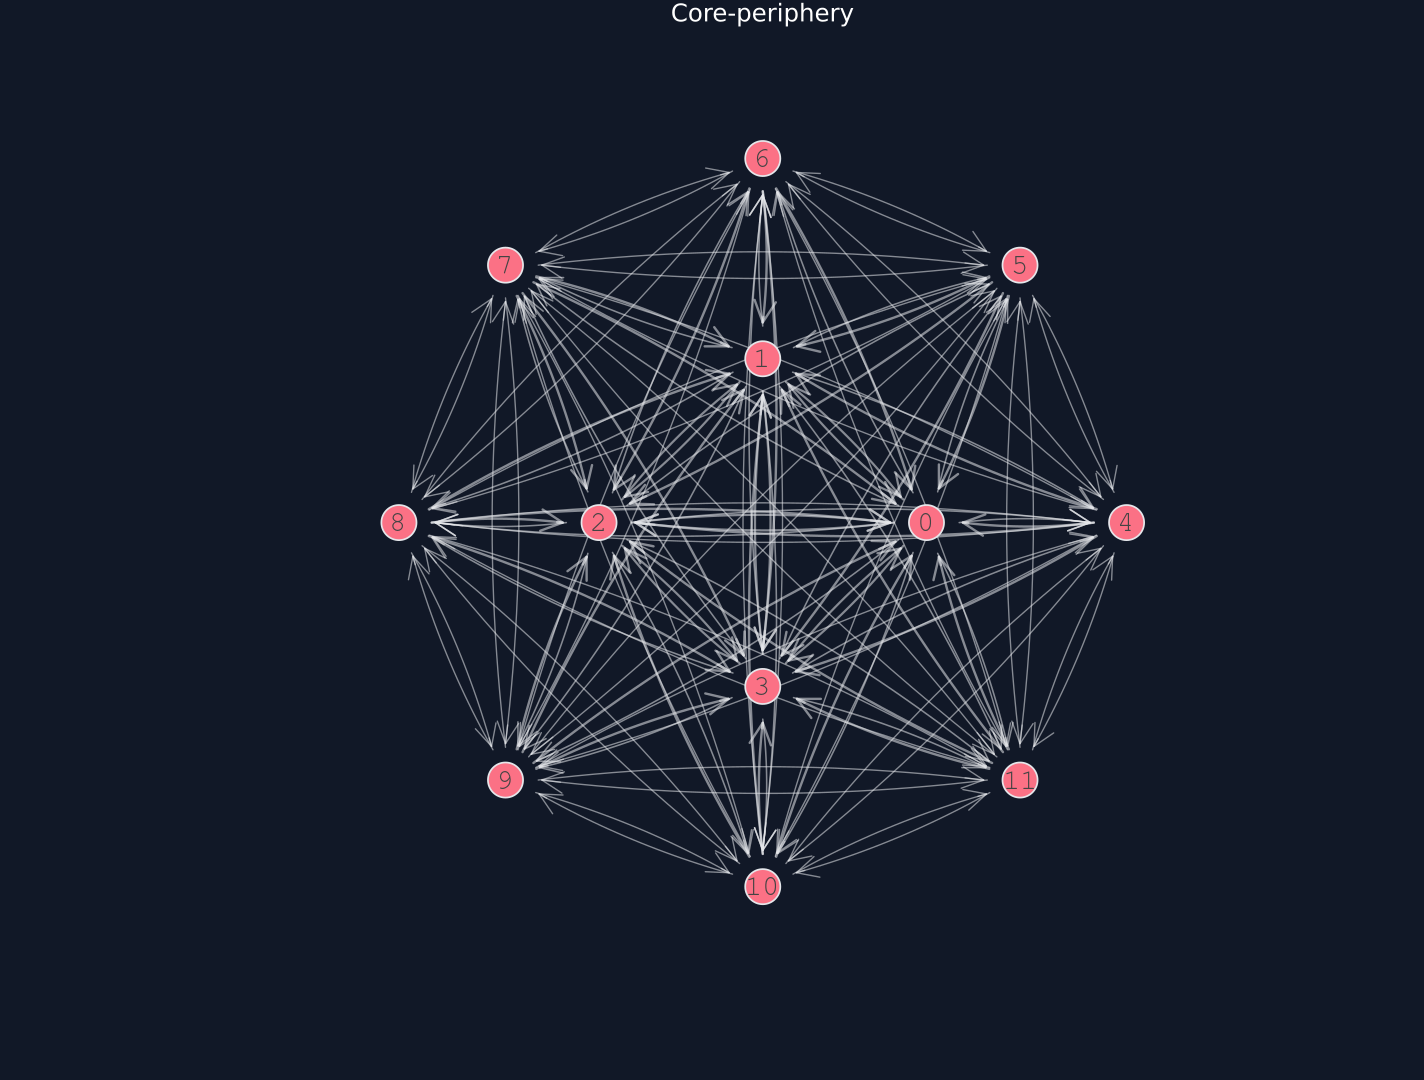

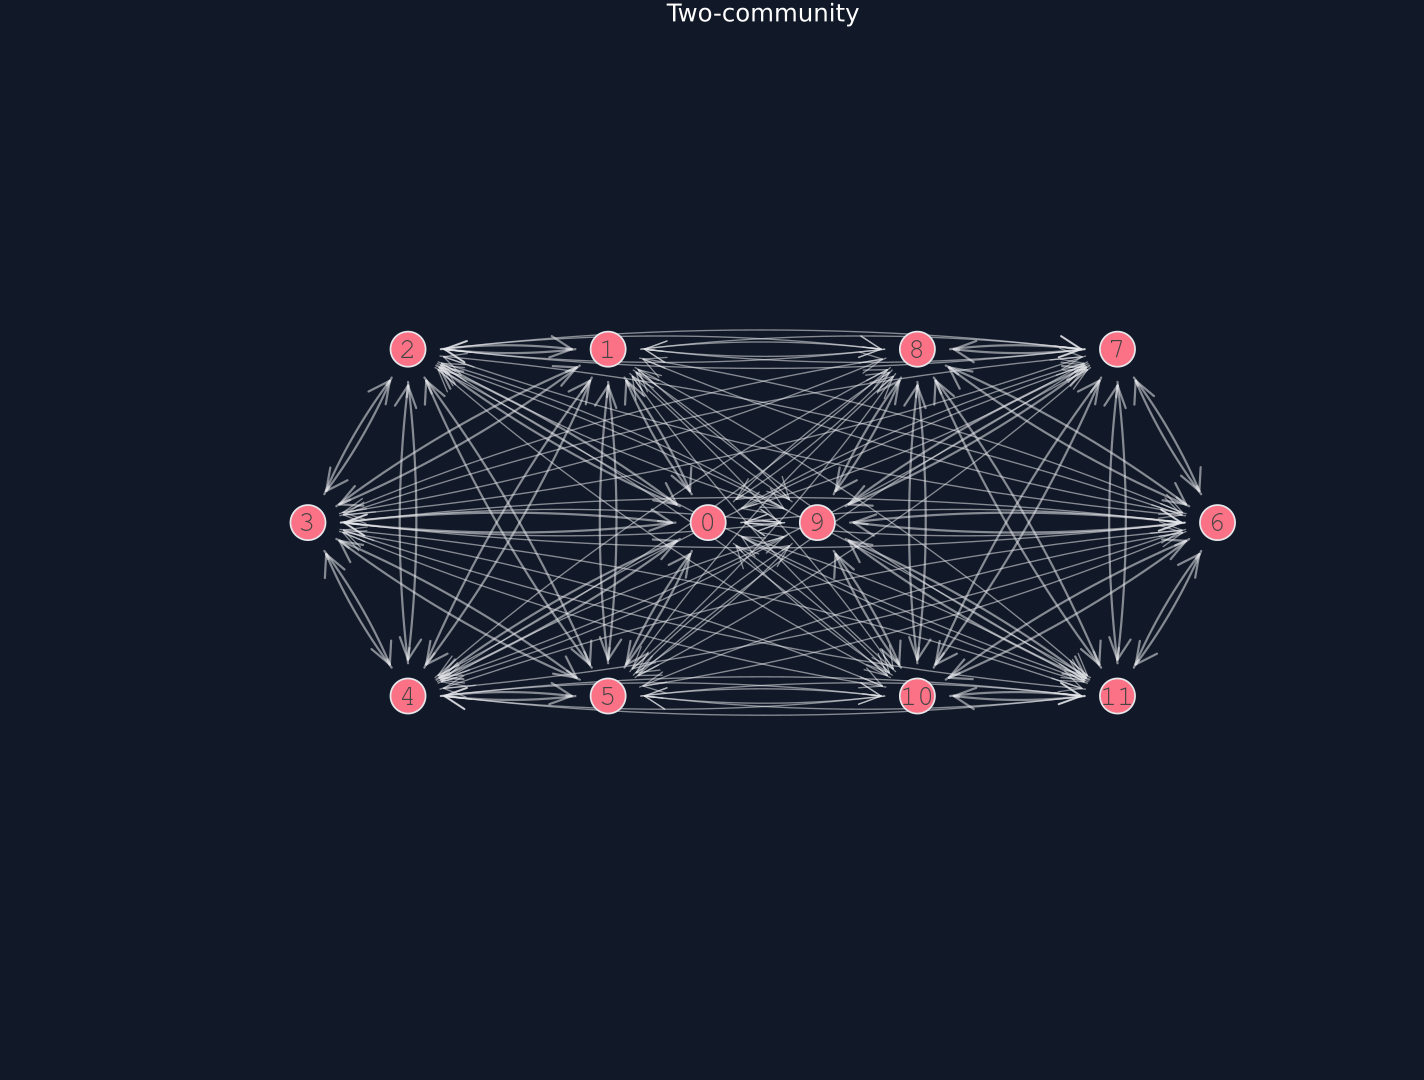

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("28_network_clearing");
using CSV, TOML, Printf, JuMP, Clarabel
include(joinpath("..","support","BookClearing.jl"))
using .BookClearing
using RiskLabAI.Optimization: eisenberg_noe_clearing
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm)
violet = "#C084FC"
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter29-"*replace(name,"_"=>"-"))
    return nothing
end
random_root = joinpath("..","data","chapter28_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root,name)
    return Matrix{Float64}(CSV.read(path,DataFrame))
end
function network_positions(name,n)
    circle(count,radius,cx=0.0) = []
    n<=3 && return [(x,0.0) for x in range(-1,1;length=n)]
    name in ["Ring","Complete"] && return circle(n,1.0)
    name=="Core-periphery" && return vcat(circle(4,0.45),circle(n-4,1.0))
    return vcat(circle(n÷2,0.55,-0.7),circle(n-n÷2,0.55,0.7))
end
function plot_network(relative,name,stem,node_values=ones(size(relative,1)))
    n = size(relative,1)
    positions = network_positions(name,n)
    figure = plot(;title=name,aspect_ratio=:equal,axis=false,grid=false,legend=false,size=(950,720),xlims=(-1.5,1.5),ylims=(-1.25,1.25))
    edge_rows = NamedTuple[]
    for debtor in 1:n,creditor in 1:n
        weight = relative[debtor,creditor]
        weight>1e-12 || continue
        push!(edge_rows,(Debtor=debtor-1,Creditor=creditor-1,relative=weight))
        start,stop = collect(positions[debtor]),collect(positions[creditor])
        direction = (stop-start)/norm(stop-start)
        start,stop = start+0.09direction,stop-0.10direction
        midpoint = (start+stop)/2+0.06norm(stop-start)*[-direction[2],direction[1]]
        curve = reduce(hcat,[(1-t)^2*start+2t*(1-t)*midpoint+t^2*stop for t in range(0,1;length=25)])
        plot!(figure,curve[1,:],curve[2,:];color="#E5E7EB",alpha=0.55,linewidth=0.8+5weight,arrow=true)
    end
    colors = [value>1e-8 ? palette.rose : palette.cyan for value in node_values]
    scatter!(figure,first.(positions),last.(positions);color=colors,markersize=13,markerstrokecolor="#E5E7EB",markerstrokewidth=0.8)
    for i in 1:n
        annotate!(figure,positions[i]...,text(string(i-1),10,"#111827",:bold))
    end
    save_figure(figure,paths,stem)
    edges = DataFrame(edge_rows)
    rename!(edges,["Debtor","Creditor","Relative liability"])
    save_data(edges,paths,stem)
    return nothing
end
function direct_linear_program(assets,nominal,relative)
    n = length(nominal)
    model = Model(Clarabel.Optimizer)
    set_silent(model)
    for name in ("tol_gap_abs","tol_gap_rel","tol_feas")
        set_optimizer_attribute(model,name,1e-14)
    end
    @variable(model,0<=payments[i=1:n]<=nominal[i])
    @constraint(model,(I-relative')*payments.<=min.(assets,nominal))
    @objective(model,Max,sum(payments))
    optimize!(model)
    @assert termination_status(model)==JuMP.MOI.OPTIMAL
    return value.(payments)
end
majorizes(source,target;tolerance=1e-12) = all(cumsum(sort(source;rev=true))[1:end-1].>=cumsum(sort(target;rev=true))[1:end-1].-tolerance)&&isapprox(sum(source),sum(target);atol=tolerance)
institution_count,internal_share,outside_share,seed = 12,0.8,0.2,2902
liabilities = 100exp.(0.45vec(primitive("baseline_normals.csv")))
liabilities ./= mean(liabilities)
structures = network_structures(institution_count)
required = reduce(hcat,[max.(liabilities-matrix'*liabilities,0) for (_,matrix) in structures])
external_assets = vec(maximum(required;dims=2))+0.12liabilities
shock_node = argmax(liabilities)
contract = DataFrame("Item"=>["Data source","Public bilateral panel found","Reason generation is necessary","Institutions","Internal liability share","Outside liability share","Random seed","Download during execution"],"Value"=>["Generated in this notebook","No","Public aggregates do not identify bilateral nominal liabilities","12","0.8","0.2","2902","None"])
table(contract,"generated_data_contract","Generation contract for the stylized network experiment.")
structure_rows,row_rows,balance_rows = NamedTuple[],NamedTuple[],NamedTuple[]
for (name,matrix) in structures
    positive = matrix[matrix.>0]
    push!(structure_rows,(Structure=name,links=count(>(0),matrix),mean_share=mean(positive),concentration=mean(sum(abs2,matrix;dims=2)),largest=maximum(matrix)))
    row_sums = vec(sum(matrix;dims=2))
    push!(row_rows,(Structure=name,smallest=minimum(row_sums),largest=maximum(row_sums),diagonal=maximum(diag(matrix)),Nonnegative=all(matrix.>=0),passed=all(isapprox.(row_sums,internal_share))&&all(diag(matrix).==0)))
    full = clearing_metrics(external_assets,liabilities,matrix)
    push!(balance_rows,(Structure=name,nominal=sum(liabilities),external=sum(external_assets),unpaid=full.total_unpaid,defaults=full.default_count,residual=full.fixed_point_residual))
end
summary = DataFrame(structure_rows)
rename!(summary,["Structure","Directed internal links","Mean positive share","Mean row squared concentration","Largest row share"])
table(summary,"network_structure_summary","Link and row-concentration summaries for the four generated structures.")
row_checks = DataFrame(row_rows)
rename!(row_checks,["Structure","Smallest row sum","Largest row sum","Diagonal maximum","Nonnegative","Row contract passes"])
@assert all(row_checks[!,"Row contract passes"])
table(row_checks,"network_row_checks","Row-sum, diagonal, and nonnegativity checks.")
balance = DataFrame(balance_rows)
rename!(balance,["Structure","Total nominal liabilities","Total external assets","Baseline total unpaid","Baseline default count","Fixed point residual"])
table(balance,"network_balance_sheet_summary","Common generated balance-sheet totals and baseline clearing results.")
for (name,matrix) in structures
    plot_network(matrix,name,replace(lowercase(name),"-"=>"_"," "=>"_")*"_network")
end


## A Fixed Shock Grid

For shock fraction $s\in[0,1]$, only the selected institution's outside assets change:

$$
e_i(s)=
\begin{cases}
(1-s)e_i(0), & i=i^{\star},\\
e_i(0), & i\ne i^{\star}.
\end{cases}
$$

Here, $i^{\star}$ is the institution with the largest generated nominal liability. A shock fraction of zero leaves its external assets unchanged, while a fraction of one removes them. Payments are recomputed separately for every network and shock size. Changes in defaults are finite outcomes for these generated balance sheets.

Row,Structure,Shock fraction,Shock amount,Total unpaid,Default count,Payment ratio,Loss amplification,Fixed point residual
,String,Float64,Float64,Float64,Int64,Float64,Float64,Float64
1,Ring,0.0,0.0,0.0,0,1.0,0.0,0.0
2,Ring,0.05,0.10809,0.0,0,1.0,0.0,0.0
3,Ring,0.1,0.21618,0.0,0,1.0,0.0,0.0
4,Ring,0.15,0.324271,0.0,0,1.0,0.0,0.0
5,Ring,0.2,0.432361,0.0,0,1.0,0.0,0.0
6,Ring,0.25,0.540451,3.33067e-16,0,1.0,6.16276e-16,2.22045e-16
7,Ring,0.3,0.648541,3.55271e-15,0,1.0,5.47801e-15,3.33067e-15
8,Ring,0.35,0.756632,0.0938528,1,0.992179,0.12404,0.0
9,Ring,0.4,0.864722,0.201943,1,0.983171,0.233535,1.11022e-16


Row,Structure,Shock fraction,Shock amount,Total unpaid,Default count,Payment ratio,Loss amplification,Fixed point residual
,String,Float64,Float64,Float64,Int64,Float64,Float64,Float64
1,Ring,0.25,0.540451,3.33067e-16,0,1.0,6.16276e-16,2.22045e-16
2,Ring,0.5,1.0809,0.418124,1,0.965156,0.386828,3.77476e-15
3,Ring,0.85,1.83753,1.17476,1,0.902104,0.639311,8.88178e-16
4,Ring,1.0,2.1618,1.49903,1,0.875081,0.693414,4.44089e-16
5,Complete,0.25,0.540451,4.44089e-16,0,1.0,8.21701e-16,4.44089e-16
6,Complete,0.5,1.0809,0.429852,1,0.964179,0.397679,4.44089e-16
7,Complete,0.85,1.83753,1.18648,1,0.901126,0.645693,3.33067e-16
8,Complete,1.0,2.1618,1.51075,1,0.874104,0.698839,1.9984e-15
9,Core-periphery,0.25,0.540451,0.273824,1,0.977181,0.506659,4.66294e-15


Row,Structure,First shock with a default,Largest default count,Number of default-set count changes,Unpaid liabilities at full shock
,String,Float64,Int64,Int64,Float64
1,Ring,0.35,1,1,1.49903
2,Complete,0.35,1,1,1.51075
3,Core-periphery,0.15,1,1,1.89518
4,Two-community,0.3,1,1,1.54669


Row,Structure,maximum_fixed_point_residual,minimum_payment_ratio,maximum_default_count,Residual passes
,String,Float64,Float64,Int64,String
1,Complete,2.66454e-15,0.874104,1,Pass
2,Core-periphery,5.55112e-15,0.842069,1,Pass
3,Ring,5.10703e-15,0.875081,1,Pass
4,Two-community,2.22045e-15,0.871109,1,Pass


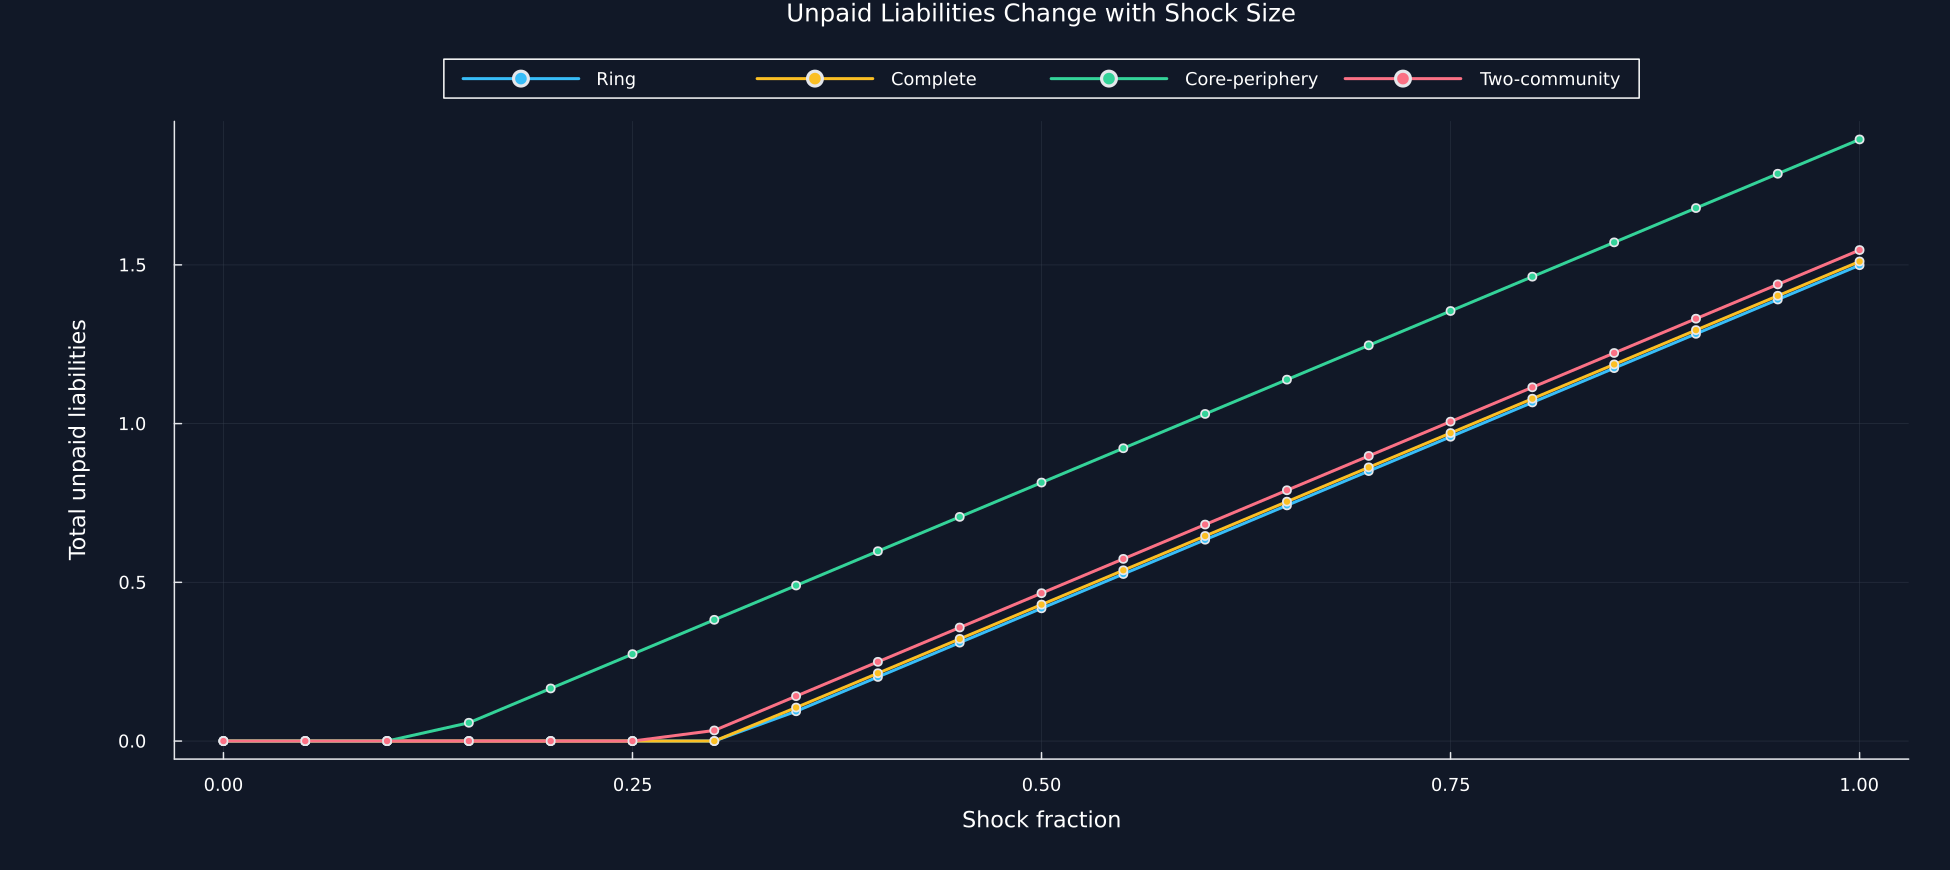

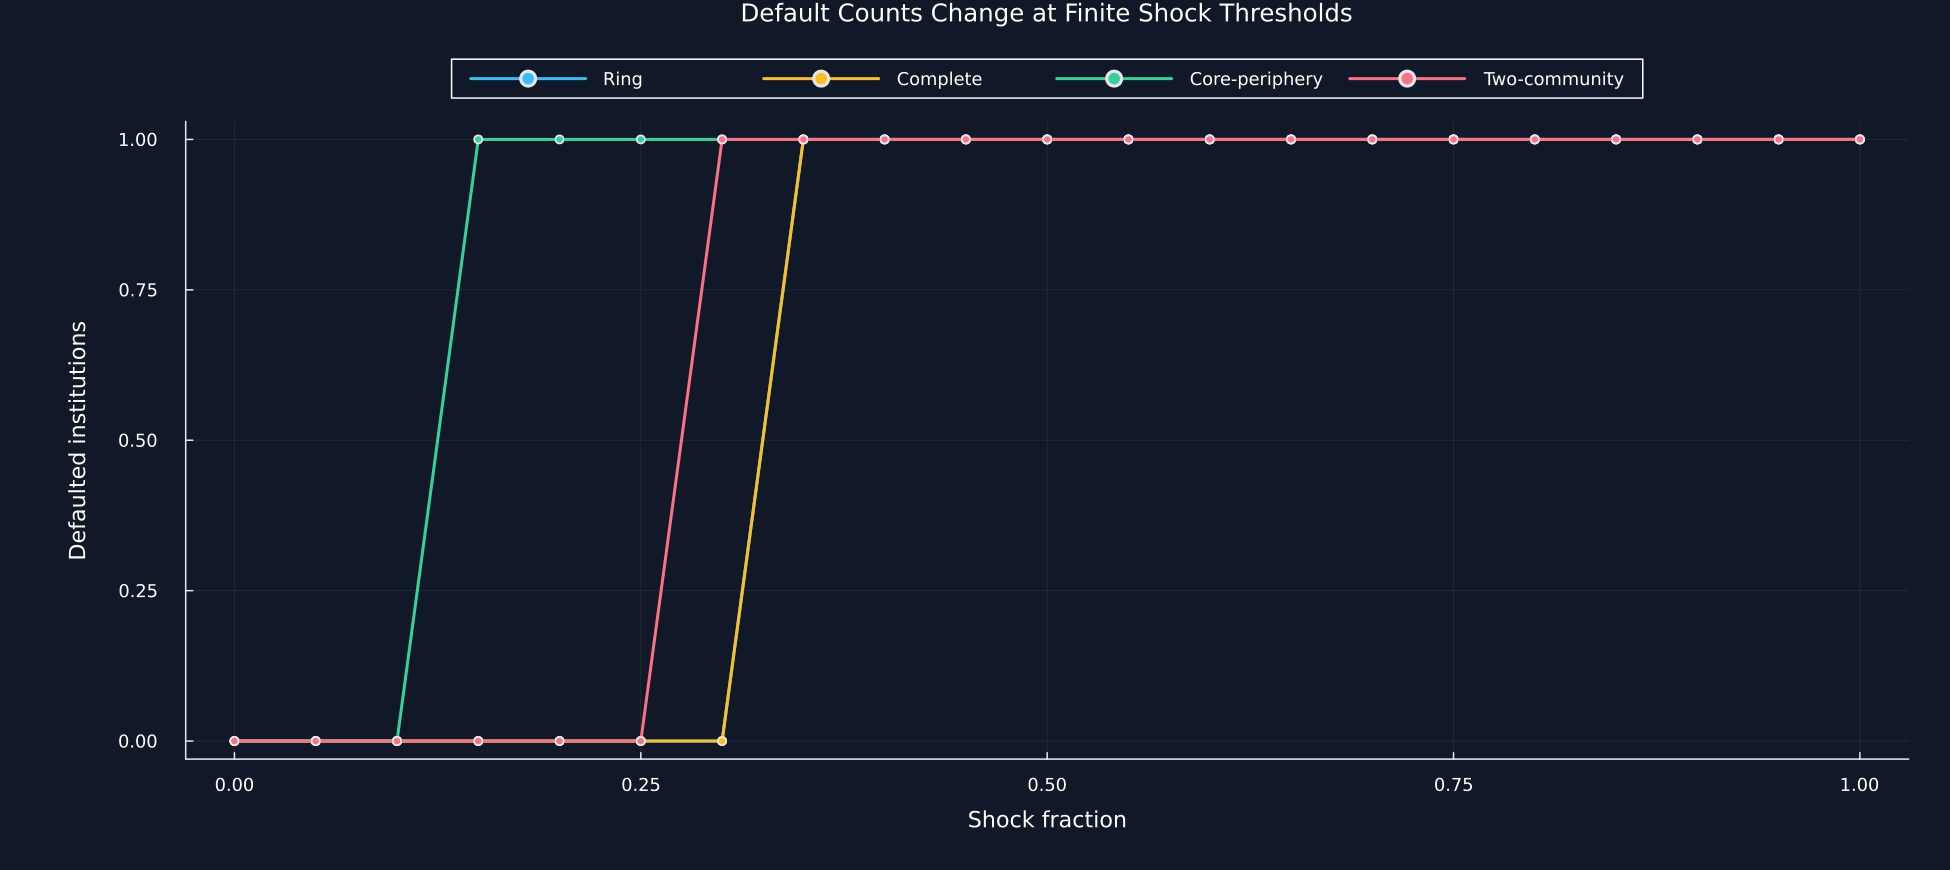

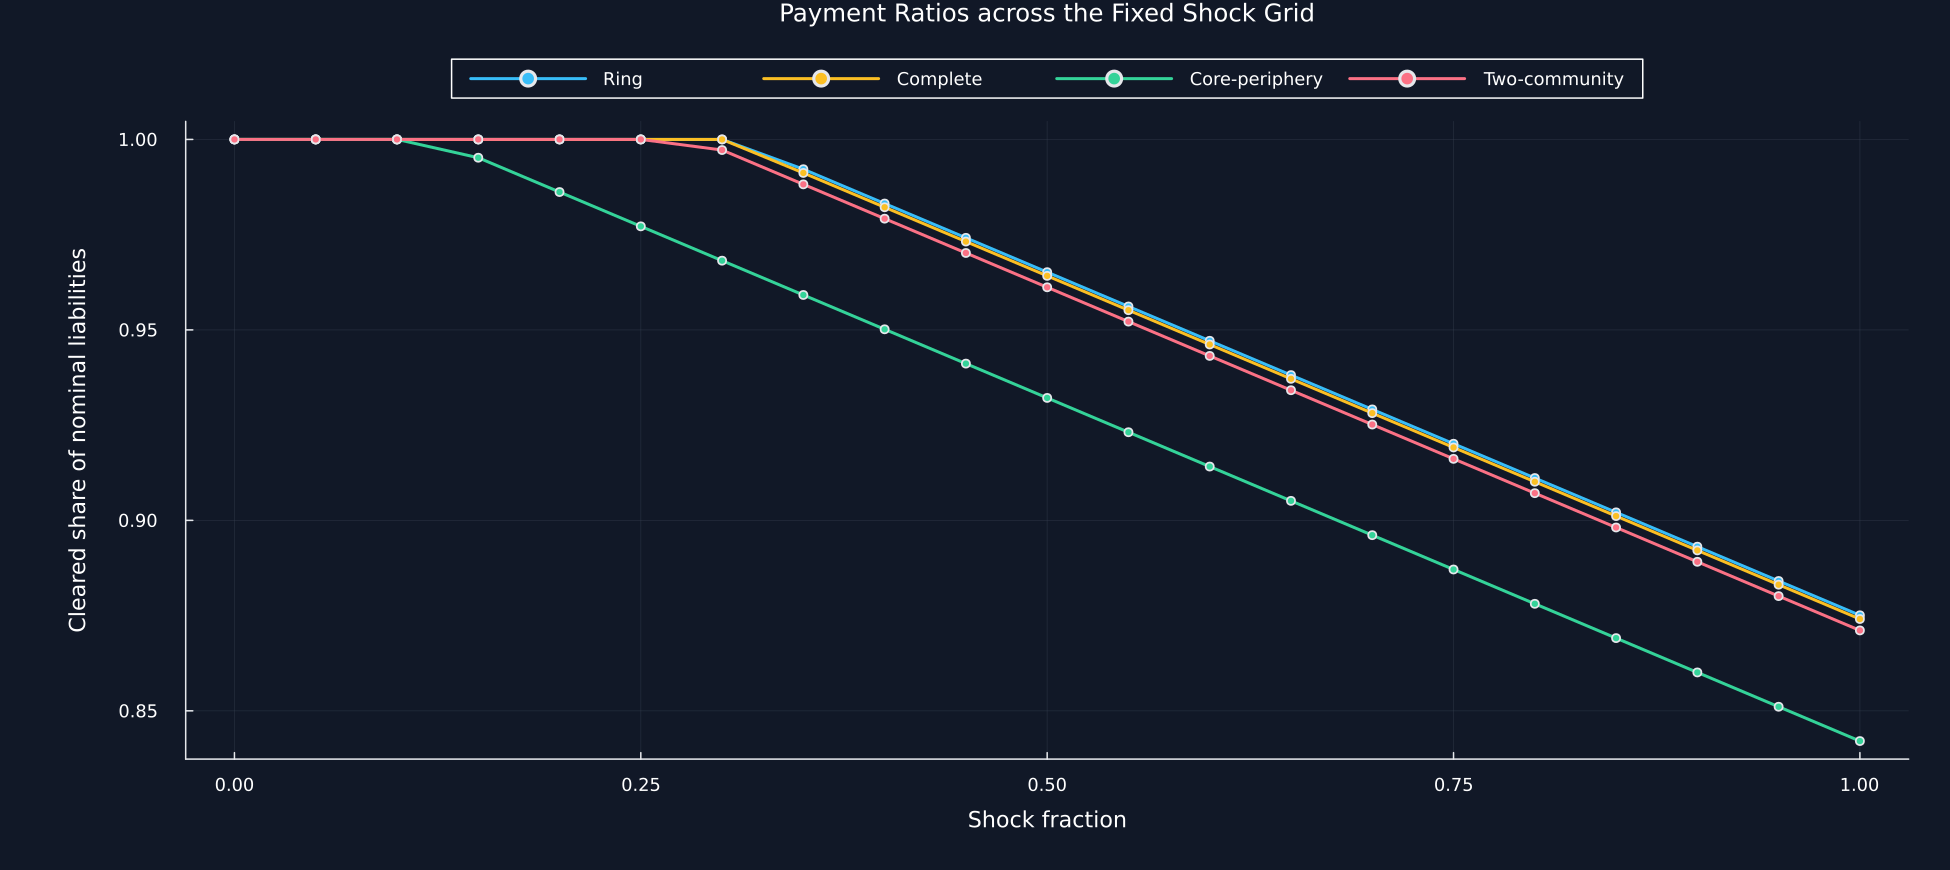

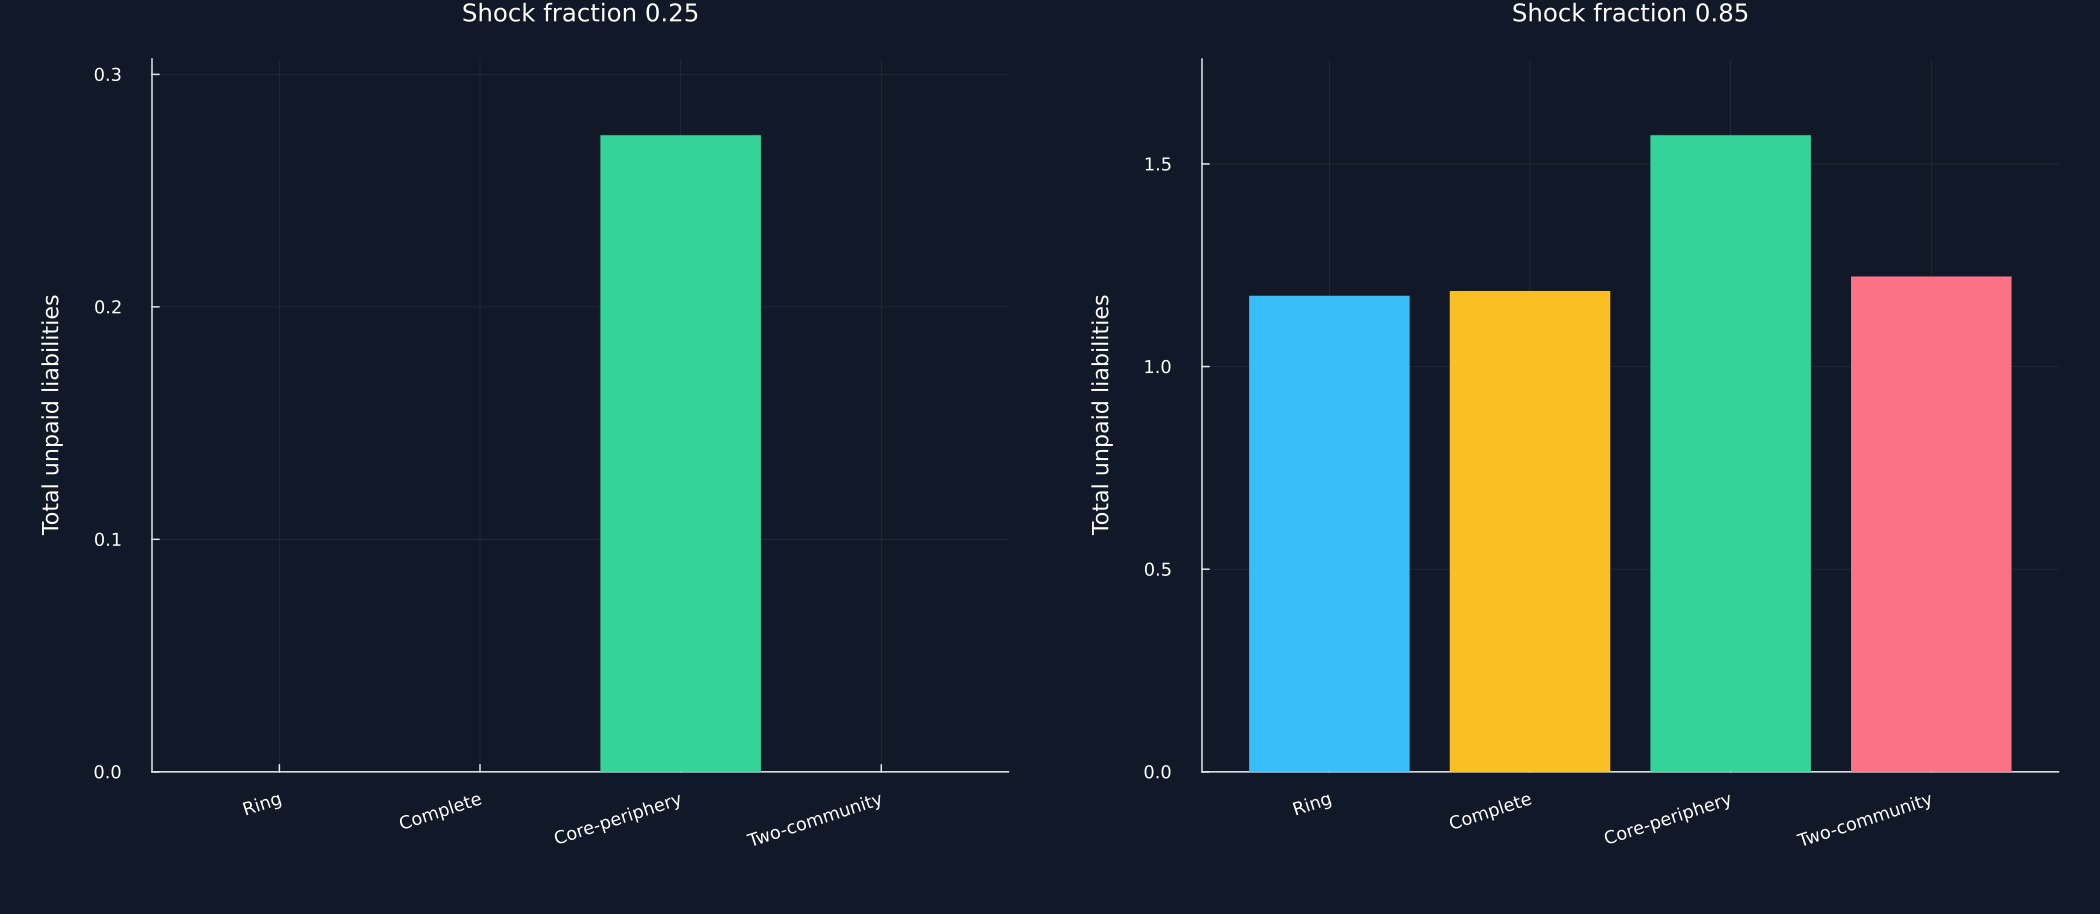

In [2]:
shock_grid = collect(0:20)./20
shock_rows = NamedTuple[]
for (name,matrix) in structures,fraction in shock_grid
    shocked_assets = copy(external_assets)
    shocked_assets[shock_node] *= 1-fraction
    result = clearing_metrics(shocked_assets,liabilities,matrix)
    amount = external_assets[shock_node]*fraction
    push!(shock_rows,(Structure=name,fraction=fraction,amount=amount,unpaid=result.total_unpaid,defaults=result.default_count,ratio=result.payment_ratio,amplification=amount>0 ? result.total_unpaid/amount : 0.0,residual=result.fixed_point_residual))
end
shock_results = DataFrame(shock_rows)
rename!(shock_results,["Structure","Shock fraction","Shock amount","Total unpaid","Default count","Payment ratio","Loss amplification","Fixed point residual"])
table(shock_results,"shock_grid_results","Clearing results over the complete generated shock grid.")
selected = shock_results[in.(shock_results[!,"Shock fraction"],Ref([0.25,0.5,0.85,1.0])),:]
table(selected,"selected_shock_outcomes","Selected small, middle, and large shock outcomes.")
threshold_rows = NamedTuple[]
for (name,_) in structures
    part = shock_results[shock_results.Structure.==name,:]
    positive = part[part[!,"Default count"].>0,:]
    first_default = isempty(positive) ? missing : minimum(positive[!,"Shock fraction"])
    push!(threshold_rows,(Structure=name,first_default=first_default,largest=maximum(part[!,"Default count"]),changes=count(!=(0),diff(part[!,"Default count"])),unpaid=only(part[part[!,"Shock fraction"].==1,"Total unpaid"])))
end
thresholds = DataFrame(threshold_rows)
rename!(thresholds,["Structure","First shock with a default","Largest default count","Number of default-set count changes","Unpaid liabilities at full shock"])
table(thresholds,"default_thresholds","First observed default thresholds and full-shock losses on the fixed grid.")
residuals = combine(groupby(shock_results,:Structure;sort=true),"Fixed point residual"=>maximum=>"maximum_fixed_point_residual","Payment ratio"=>minimum=>"minimum_payment_ratio","Default count"=>maximum=>"maximum_default_count")
residuals[!,"Residual passes"] = residuals.maximum_fixed_point_residual.<=1e-8
@assert all(residuals[!,"Residual passes"])
table(residuals,"shock_fixed_point_checks","Fixed point residuals and range checks across the shock grid.")
structure_colors = [palette.cyan,palette.amber,palette.green,palette.rose]
for (metric,ylabel,title,stem) in [("Total unpaid","Total unpaid liabilities","Unpaid Liabilities Change with Shock Size","shock_unpaid_curves"),("Default count","Defaulted institutions","Default Counts Change at Finite Shock Thresholds","shock_default_counts"),("Payment ratio","Cleared share of nominal liabilities","Payment Ratios across the Fixed Shock Grid","shock_payment_ratios")]
    data = shock_results[:,["Structure","Shock fraction",metric]]
    save_data(data,paths,stem)
    figure = plot(;xlabel="Shock fraction",ylabel,title,legend=:outertop,legend_columns=4,size=(1300,580),left_margin=16Plots.mm)
    for ((name,_),color) in zip(structures,structure_colors)
        part = data[data.Structure.==name,:]
        plot!(figure,part[!,"Shock fraction"],part[!,metric];color,marker=:circle,markersize=3,label=name)
    end
    save_figure(figure,paths,stem)
end
snapshot = selected[in.(selected[!,"Shock fraction"],Ref([0.25,0.85])),["Structure","Shock fraction","Total unpaid","Default count"]]
save_data(snapshot,paths,"small_large_shock_comparison")
panels = Any[]
for fraction in [0.25,0.85]
    part = snapshot[snapshot[!,"Shock fraction"].==fraction,:]
    high = maximum(part[!,"Total unpaid"])
    push!(panels,bar(1:4,part[!,"Total unpaid"];color=structure_colors,linealpha=0,xticks=(1:4,part.Structure),xrotation=18,ylabel="Total unpaid liabilities",title=@sprintf("Shock fraction %g",fraction),legend=false,ylims=(0,high==0 ? 0.05 : 1.12high),bottom_margin=15Plots.mm))
end
save_figure(plot(panels...;layout=(1,2),size=(1400,610)),paths,"small_large_shock_comparison")


## Repeated Generated Balance Sheets

For generated run $b$, liabilities and asset cushions vary while every network keeps the same row-sum rule. At shock sizes $s\in\{0.25,0.85\}$, the recorded loss is

$$
U_{b,m}(s)=\sum_{i=1}^{12}\left(\overline p_{b,i}-p_{b,m,i}(s)\right),
$$

where $m$ identifies the network structure. The quantity $U_{b,m}(s)$ is total unpaid liability in one generated system. Two hundred fixed seeds show how much the finite ordering depends on the generated balance sheet. They do not form a population estimate.

Row,Setting,Value
,String,String
1,Generated runs,200
2,First seed,290200
3,Last seed,290399
4,Institutions per run,12
5,Shock fractions,0.25 and 0.85
6,Rows per structure,400


Row,Shock fraction,Structure,mean,std,median,min,max
,Float64,String,Float64,Float64,Float64,Float64,Float64
1,0.25,Complete,0.235897,1.4191,1.42109e-14,0.0,12.625
2,0.25,Core-periphery,4.46425,8.29115,1.20792e-13,0.0,47.8291
3,0.25,Ring,2.19264,6.1776,2.84217e-14,0.0,42.6236
4,0.25,Two-community,0.349516,1.75971,1.42109e-14,0.0,15.0559
5,0.85,Complete,18.9899,37.6369,6.75016e-14,0.0,197.778
6,0.85,Core-periphery,32.1444,44.8202,18.1717,0.0,237.212
7,0.85,Ring,27.7024,41.9587,8.02883,0.0,221.867
8,0.85,Two-community,20.0077,38.5187,5.68434e-14,0.0,204.782


Row,Shock fraction,Mean-loss rank,Structure,Mean total unpaid
,Float64,Int64,String,Float64
1,0.25,1,Complete,0.235897
2,0.25,2,Two-community,0.349516
3,0.25,3,Ring,2.19264
4,0.25,4,Core-periphery,4.46425
5,0.85,1,Complete,18.9899
6,0.85,2,Two-community,20.0077
7,0.85,3,Ring,27.7024
8,0.85,4,Core-periphery,32.1444


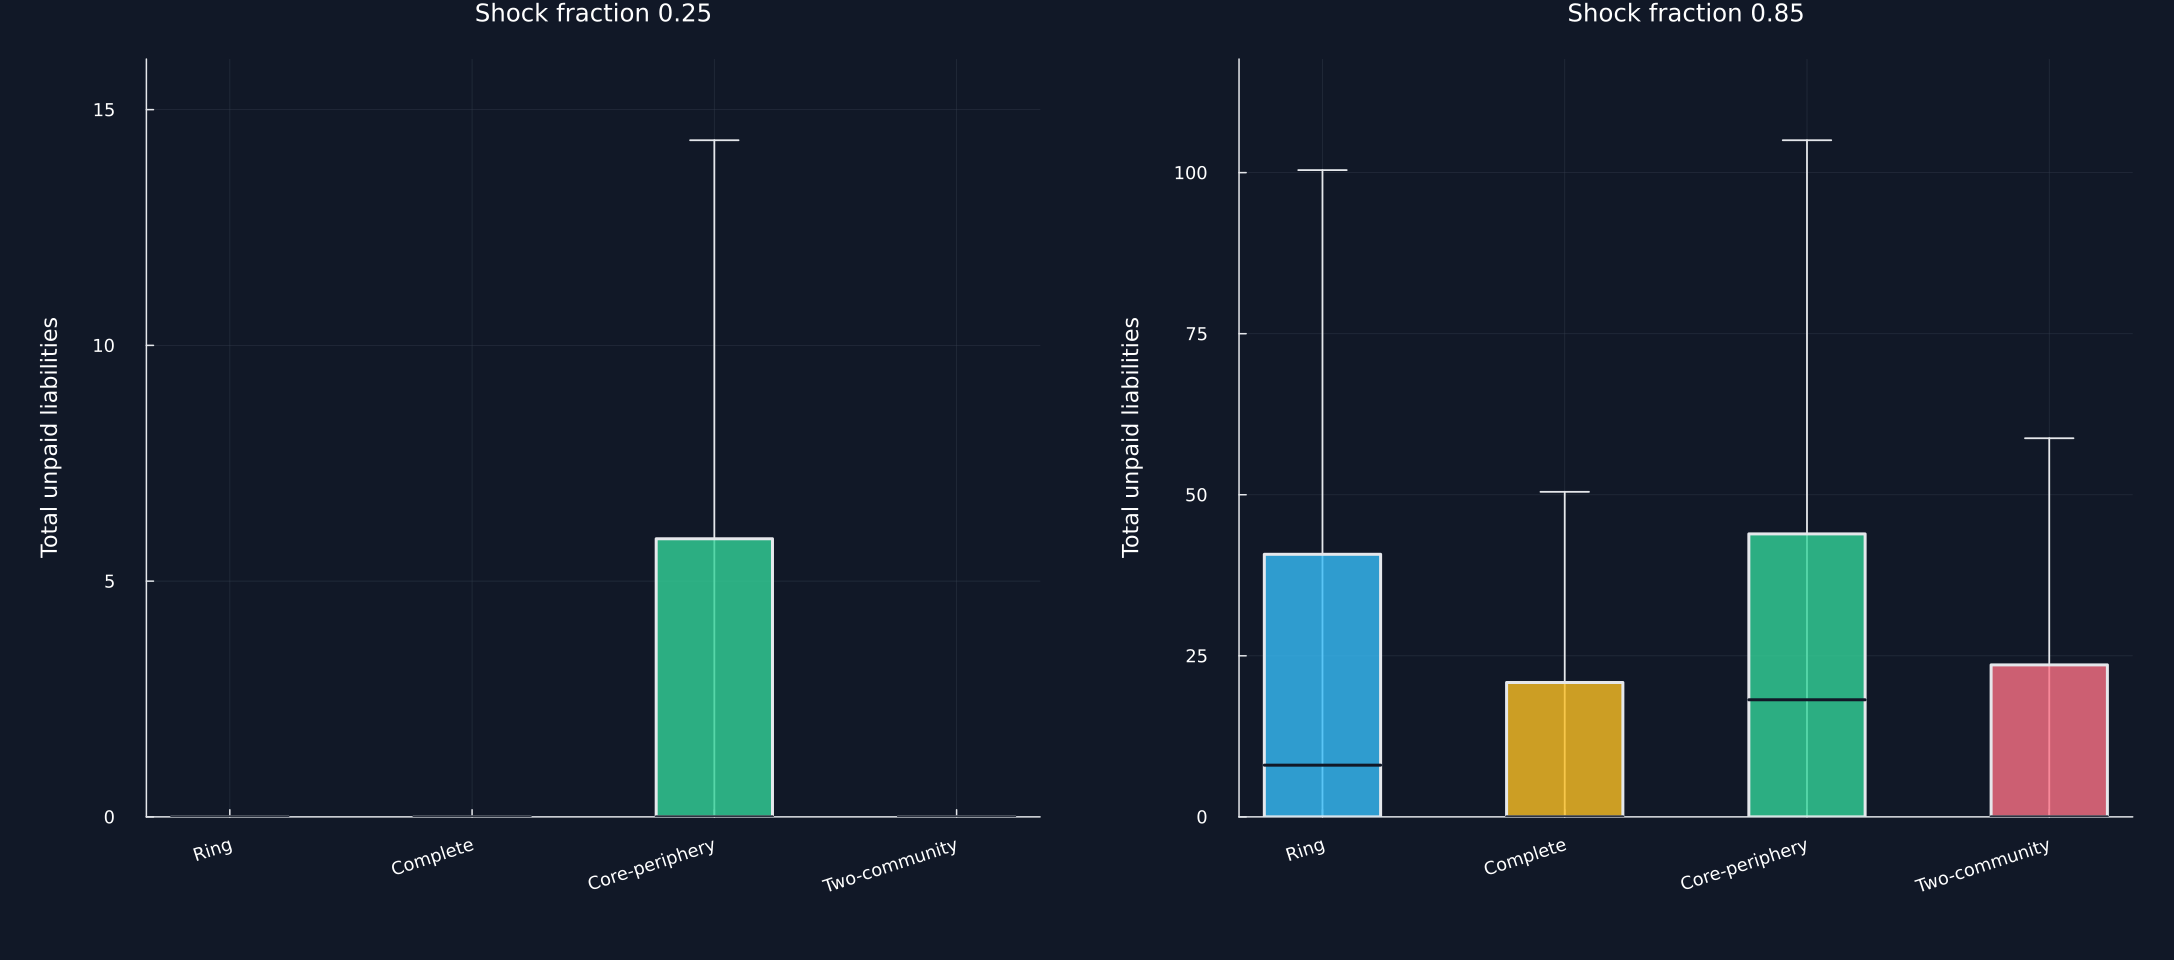

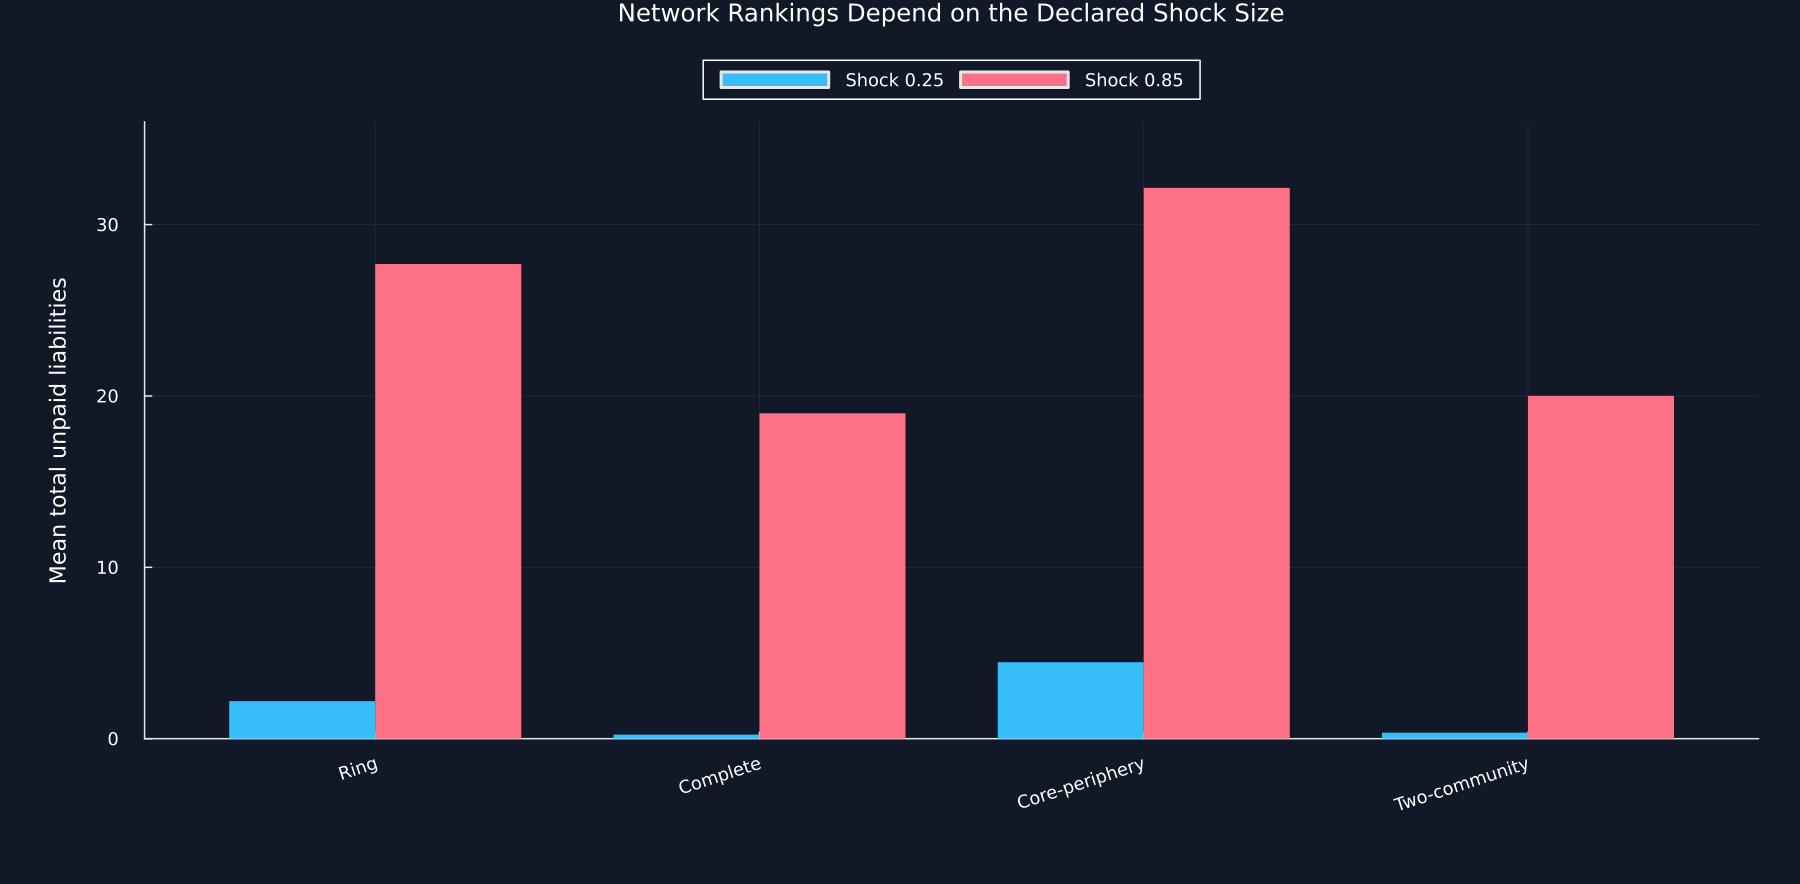

In [3]:
repeated_normals,repeated_uniforms,repeated_nodes = primitive("repeated_normals.csv"),primitive("repeated_uniforms.csv"),Int.(primitive("repeated_nodes.csv"))
seed_rows = NamedTuple[]
for draw in 1:200
    draw_liabilities = exp.(0.55repeated_normals[draw,:])
    draw_liabilities = 100draw_liabilities/mean(draw_liabilities)
    draw_required = reduce(hcat,[max.(draw_liabilities-matrix'*draw_liabilities,0) for (_,matrix) in structures])
    cushion = (0.04.+0.16repeated_uniforms[draw,:]).*draw_liabilities
    draw_assets = vec(maximum(draw_required;dims=2))+cushion
    node = repeated_nodes[draw]
    for fraction in [0.25,0.85]
        shocked = copy(draw_assets)
        shocked[node] *= 1-fraction
        for (name,matrix) in structures
            result = clearing_metrics(shocked,draw_liabilities,matrix)
            push!(seed_rows,(Draw=draw-1,Structure=name,fraction=fraction,node=node-1,unpaid=result.total_unpaid,defaults=result.default_count,residual=result.fixed_point_residual))
        end
    end
end
seed_results = DataFrame(seed_rows)
rename!(seed_results,["Draw","Structure","Shock fraction","Shock node","Total unpaid","Default count","Fixed point residual"])
@assert nrow(seed_results)==1600
seed_contract = DataFrame("Setting"=>["Generated runs","First seed","Last seed","Institutions per run","Shock fractions","Rows per structure"],"Value"=>["200","290200","290399","12","0.25 and 0.85","400"])
table(seed_contract,"seed_experiment_contract","Fixed settings for the repeated generated balance-sheet experiment.")
seed_summary = combine(groupby(seed_results,["Shock fraction","Structure"];sort=true),"Total unpaid"=>mean=>"mean","Total unpaid"=>std=>"std","Total unpaid"=>median=>"median","Total unpaid"=>minimum=>"min","Total unpaid"=>maximum=>"max")
table(seed_summary,"seed_unpaid_summary","Distribution summaries for total unpaid liabilities over two hundred generated runs.")
rank_rows = NamedTuple[]
for fraction in [0.25,0.85]
    means = sort(seed_summary[seed_summary[!,"Shock fraction"].==fraction,:],:mean;alg=MergeSort)
    for (rank,row) in enumerate(eachrow(means))
        push!(rank_rows,(fraction=fraction,rank=rank,Structure=row.Structure,mean=row.mean))
    end
end
ranking = DataFrame(rank_rows)
rename!(ranking,["Shock fraction","Mean-loss rank","Structure","Mean total unpaid"])
table(ranking,"small_large_ranking","Finite mean-loss orderings at the two declared shock sizes.")
save_data(seed_results,paths,"seed_unpaid_distributions")
function box_panel(groups,labels,title)
    panel = plot(;title,ylabel="Total unpaid liabilities",xticks=(1:length(groups),labels),xrotation=18,legend=false,bottom_margin=15Plots.mm)
    largest = 0.0
    for (index,(values,color)) in enumerate(zip(groups,structure_colors))
        q1,center,q3 = quantile(values,[0.25,0.5,0.75])
        spread = q3-q1
        low,high = minimum(values[values.>=q1-1.5spread]),maximum(values[values.<=q3+1.5spread])
        largest = max(largest,high)
        plot!(panel,[index,index],[low,high];color="#E5E7EB",linewidth=1.2)
        for value in [low,high]
            plot!(panel,[index-0.10,index+0.10],[value,value];color="#E5E7EB",linewidth=1.2)
        end
        plot!(panel,Shape([index-0.24,index+0.24,index+0.24,index-0.24],[q1,q1,q3,q3]);color,fillalpha=0.8,linecolor="#E5E7EB")
        plot!(panel,[index-0.24,index+0.24],[center,center];color="#111827",linewidth=2)
    end
    plot!(panel;ylims=(0,largest==0 ? 1.0 : 1.12largest))
    return panel
end
panels = Any[]
for fraction in [0.25,0.85]
    part = seed_results[seed_results[!,"Shock fraction"].==fraction,:]
    groups = [part[part.Structure.==name,"Total unpaid"] for (name,_) in structures]
    push!(panels,box_panel(groups,first.(structures),@sprintf("Shock fraction %g",fraction)))
end
save_figure(plot(panels...;layout=(1,2),size=(1450,640)),paths,"seed_unpaid_distributions")
mean_plot = seed_summary[:,["Shock fraction","Structure","mean"]]
rename!(mean_plot,"mean"=>"Mean total unpaid")
save_data(mean_plot,paths,"small_large_mean_losses")
figure = plot(;ylabel="Mean total unpaid liabilities",title="Network Rankings Depend on the Declared Shock Size",xticks=(1:4,first.(structures)),xrotation=18,legend=:outertop,legend_columns=2,size=(1200,590),bottom_margin=15Plots.mm,ylims=(0,1.12maximum(mean_plot[!,"Mean total unpaid"])))
for (offset,fraction,color) in [(-0.19,0.25,palette.cyan),(0.19,0.85,palette.rose)]
    part = mean_plot[mean_plot[!,"Shock fraction"].==fraction,:]
    values = [only(part[part.Structure.==name,"Mean total unpaid"]) for (name,_) in structures]
    bar!(figure,(1:4).+offset,values;bar_width=0.38,color,linealpha=0,label=@sprintf("Shock %g",fraction))
end
save_figure(figure,paths,"small_large_mean_losses")
